# **Week 7: Text and Multimodal AI**
## **Reading Text, Documents and Images Together (Recycling Waste Domain)**

| | |
|---|---|
| **Student** | Muhammad Luqman Khan |
| **Subject** | Introduction to Applied AI |


In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__)

spaCy 3.8.16


In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


## **Part 1: TF-IDF by Hand**

### **1. What I Did**
Before trusting the library, I reproduced scikit-learn's TF-IDF by hand on three tiny documents: **"win free cash now"**, **"call me now"** and **"free call now"**. scikit-learn uses smooth IDF, **idf = ln[(1 + N) / (1 + df)] + 1**, and then scales each document vector to length 1.

### **2. IDF Arithmetic**
Here **N = 3** documents.

| Word | df | IDF working | IDF |
|---|---|---|---|
| win | 1 | ln(4 / 2) + 1 | **1.693** |
| cash | 1 | ln(4 / 2) + 1 | **1.693** |
| free | 2 | ln(4 / 3) + 1 = 0.288 + 1 | **1.288** |
| now | 3 | ln(4 / 4) + 1 = 0 + 1 | **1.000** |

**Why "now" gets the lowest weight:** it appears in **all 3 documents**, so it cannot help tell one document from another. The log term becomes 0 and only the +1 remains. Rare words such as "win" and "cash" get the highest weight.

### **3. Check Against the Library**
For d1, my hand calculation gave **win 0.584, free 0.445, cash 0.584, now 0.345**. This is **identical** to the TfidfVectorizer table, so the library does exactly what the formula says. The order also follows the IDF values: win = cash > free > now.

### **4. Cosine Similarity of d2 and d3**
Both vectors already have length 1, so cosine similarity is just the dot product. Only the words shared by d2 and d3 count: "call" and "now" (d2 has no "free" and d3 has no "me").

| Shared word | d2 | d3 | Product |
|---|---|---|---|
| call | 0.548 | 0.620 | 0.340 |
| now | 0.425 | 0.481 | 0.204 |

**Cosine = 0.340 + 0.204 = 0.544**, which matches the **0.54** on slide 10.

**What it means:** d2 and d3 are fairly similar because they share "call" and "now", but not identical, because d2 has "me" and d3 has "free".

In [3]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



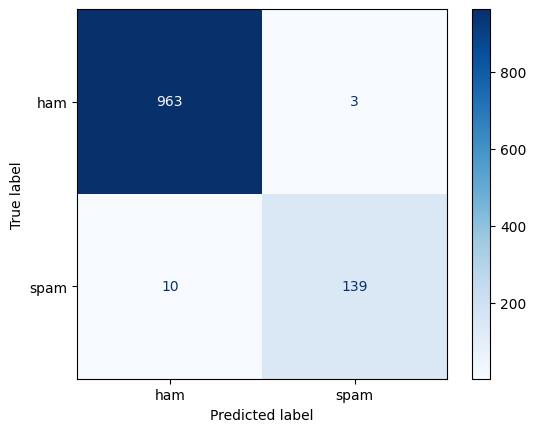

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [5]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [6]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

# Robustness to spelling tricks
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print(dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


In [7]:
# Char model: precision and recall
p_char = char_clf.predict(X_te)
print(classification_report(y_te, p_char, target_names=['ham', 'spam'], digits=3))

# Word model: misclassified messages
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                         

In [8]:
mine = ['Mubarak ho! Aap ne 10000$ jeeta hai, abhi is link par click karein', 'Bhai free ho to call kar laina kal milty hain']
print('word:', dict(zip(mine, word_clf.predict_proba(mine)[:, 1].round(2))))
print('char:', dict(zip(mine, char_clf.predict_proba(mine)[:, 1].round(2))))

word: {'Mubarak ho! Aap ne 10000$ jeeta hai, abhi is link par click karein': np.float64(0.24), 'Bhai free ho to call kar laina kal milty hain': np.float64(0.86)}
char: {'Mubarak ho! Aap ne 10000$ jeeta hai, abhi is link par click karein': np.float64(0.32), 'Bhai free ho to call kar laina kal milty hain': np.float64(0.32)}


## **Part 2: Text Classification (Word vs Character N-grams)**

### **1. Dataset and Baseline**
I used the **SMS Spam Collection** dataset: **5,572 messages**, of which **4,825 are ham** and **747 are spam**, so the **spam share is 0.134**. A lazy model that always says "ham" would already score **0.866 accuracy**, so accuracy alone is a weak yardstick. I report **macro-F1** and the spam class's **precision and recall** instead.

The split is **80/20 and stratified** (`random_state=42`), giving a test set of **1,115 messages (966 ham, 149 spam)**. Both models use the same split, so they are compared fairly.

### **2. Word vs Character Model**
| Model | Features | Macro-F1 | Accuracy | Spam precision | Spam recall |
|---|---|---|---|---|---|
| Word 1-2 grams | 12,128 | 0.974 | 0.988 | 0.979 | 0.933 |
| Char 2-5 grams | 36,449 | **0.982** | **0.992** | **0.986** | **0.953** |

**What the numbers mean:** the character model is better on every metric. Counting from the recall and precision values, it makes **9 mistakes** (7 missed spam, 2 false alarms) against **13** for the word model (10 missed spam, 3 false alarms). That is about **3 more spam messages caught** out of 149, at the cost of about **three times as many features**.

**Caution:** this is a single split and the gap is only a few messages, so I treat the character model as **slightly better**, not proven better.

### **3. What the Word Model Learned**
- **Most spam-like:** call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
- **Most ham-like:** my, me, ok, that, it, but, ll, gt, lt, can, what, da

**Sensible features:** **txt, text, reply, claim, stop, free, mobile** and **www** are real spam language (claim a prize, reply STOP, visit a website). The ham words **my, me, ok, ll** and **da** come from everyday chat.

**Shortcut-like features:**
- **uk:** most spam in this dataset comes from the UK, so this reflects **where the data was collected**, not what spam is.
- **to, your, call:** very common words that happen to appear more often in spam here.
- **gt, lt:** these are leftovers of the HTML codes `&gt;` and `&lt;` in the data. They say **nothing about the meaning** of a message.

**Why this matters:** a shortcut such as "call" can push a normal message towards spam, as the errors and my own test below show.

### **4. Error Analysis (Word Model, 13 Errors)**
The word model made **13 mistakes**: **10 missed spam** and **3 ham messages flagged as spam**. I read every one and classified it as a **model error** (the label is right and the model is wrong), a **label error** (the label itself is wrong) or **genuinely ambiguous** (reasonable people could disagree).

| Index | Message (shortened) | True label | p_spam | Type |
|---|---|---|---|---|
| 750 | "...old ladies running around with tattoos?" | spam | 0.088 | Ambiguous |
| 2246 | "Hi ya babe... scammers getting smart..." | spam | 0.144 | Ambiguous |
| 3979 | "ringtoneking 84484" | spam | 0.192 | Model error |
| 1429 | "For sale - arsenal dartboard..." | spam | 0.211 | Ambiguous |
| 2821 | "ROMCAPspam Everyone around should be responding well..." | spam | 0.252 | Model error |
| 3358 | "Sorry I missed your call... I'm on 07090201529" | spam | 0.280 | Model error |
| 5449 | "Latest News! Police station toilet stolen..." | spam | 0.315 | Ambiguous |
| 5 | "FreeMsg Hey there darling... std chgs" | spam | 0.412 | Model error |
| 2351 | "Download as many ringtones... Txt Sir to 80082" | spam | 0.425 | Model error |
| 1268 | "Can U get 2 phone NOW?... Call me NOW" | spam | 0.465 | Model error |
| 5044 | "We have sent JD for Customer Service cum Accounts Executive..." | ham | 0.621 | Model error |
| 152 | "Ok... Ur typical reply..." | ham | 0.636 | Model error |
| 573 | "Waiting for your call." | ham | 0.853 | Model error |

**Total: 9 model errors, 4 ambiguous, 0 confirmed label errors.**

**Patterns I noticed:**
- **Near misses:** three missed spam messages (**0.412, 0.425, 0.465**) were close to the 0.5 line. A lower threshold might catch them, but it would also raise false alarms, and I did **not** test this.
- **Messages the model never had a chance on:** "ringtoneking 84484" is only two tokens, and in "ROMCAPspam" the word "spam" is glued to another word, so it is not seen as a separate feature.
- **The shortcut at work:** the worst false alarm, "Waiting for your call." (ham), scored **0.853** because "call" and "your" are both strong spam features, which is exactly the shortcut found in section 3.
- **Ambiguous cases:** "old ladies with tattoos", "arsenal dartboard for sale" and "Police station toilet stolen" read like jokes or adverts, and "scammers getting smart" is a **warning about** a scam. The spam label is debatable, but I cannot prove any of them wrong, so I did **not** call them label errors.

### **5. My Own Tricky Messages**
| Message | Meaning | True label | Word model | Char model |
|---|---|---|---|---|
| `Mubarak ho! Aap ne 10000$ jeeta hai, abhi is link par click karein` | "Congratulations! You won $10,000, click this link now" | spam | 0.24 (**missed**) | 0.32 (**missed**) |
| `Bhai free ho to call kar laina kal milty hain` | "Brother, if you are free, call me, let's meet tomorrow" | ham | **0.86 (wrong)** | **0.32 (correct)** |

- **Roman Urdu spam:** **both** models missed it. They were trained on English messages, so words such as "mubarak", "jeeta" and "click karein" are mostly unseen.
- **Ham with spam words:** the word model was fooled by "**free**" and "**call**" (**0.86**), but the character model stayed at **0.32**. A likely reason is that the character model spreads its weight over many small letter patterns instead of resting on single words, but I tested **only this one message**, so this is a hypothesis.

The lab's own examples agreed: the character model gave **0.85** to the disguised spam `W1N a FR33 pr1ze!! txt CLAIM now` and **0.12** to the Roman Urdu ham `kal milte hain, 5 baje`.

### **6. Conclusion and Limitations**
The **character model is the stronger choice** (macro-F1 **0.982 vs 0.974**) and handles spelling tricks better. **Neither model understands Roman Urdu spam**, so I would need Roman Urdu training examples before using it on local messages. A wrong spam alarm on a real message (like "Waiting for your call.") is costly, so a **human should review flagged messages**.

**Limitations:** one 80/20 split, an English-only dataset with UK-heavy spam, and only two tricky messages of my own.

In [9]:
my_sentences = [
    # Sentences 1-5: rules inhi se likhenge
    'Muhammad Luqman Khan trained a ResNet-18 on the Garbage Classification dataset from Kaggle on 24 October 2026.',
    'Dr. Faiz Ahmad checked the project of Muhammad Luqman Khan at the Department of Electronics.',
    'Lahore Waste Management Company paid Rs. 18,000 to Raheel for scrap metal on 05/11/2026.',
    'Call Hanzala Traders at 0312-5558899 to sell old batteries in Rawalpindi.',
    'Ateeq ur Rehman of EcoSort Pakistan received PKR 1,200,000 from Telenor on 12/10/2026.',
    # Sentences 6-10: sirf score karne ke liye (naye naam, naye format)
    'Abuzar from Faisalabad sold glass bottles to Nosherwan Recycling for Rs. 25,000.',
    'The truck from Peshawar reached Port Qasim on Friday.',
    'Rafi of NUST presented a recycling study on 3 December 2026.',
    'Green Earth Recyclers opened a plant in Multan and paid PKR 75,000 as rent.',
    'Email Shoaib at shoaib@greenearth.pk before 20/12/2026.']

my_gold = [
    {('Muhammad Luqman Khan', 'PERSON'), ('Kaggle', 'ORG'), ('24 October 2026', 'DATE')},
    {('Faiz Ahmad', 'PERSON'), ('Muhammad Luqman Khan', 'PERSON'), ('Department of Electronics', 'ORG')},
    {('Lahore Waste Management Company', 'ORG'), ('Rs. 18,000', 'MONEY'), ('Raheel', 'PERSON'), ('05/11/2026', 'DATE')},
    {('Hanzala Traders', 'ORG'), ('Rawalpindi', 'GPE')},
    {('Ateeq ur Rehman', 'PERSON'), ('EcoSort Pakistan', 'ORG'), ('PKR 1,200,000', 'MONEY'), ('Telenor', 'ORG'), ('12/10/2026', 'DATE')},
    {('Abuzar', 'PERSON'), ('Faisalabad', 'GPE'), ('Nosherwan Recycling', 'ORG'), ('Rs. 25,000', 'MONEY')},
    {('Peshawar', 'GPE'), ('Port Qasim', 'FAC'), ('Friday', 'DATE')},
    {('Rafi', 'PERSON'), ('NUST', 'ORG'), ('3 December 2026', 'DATE')},
    {('Green Earth Recyclers', 'ORG'), ('Multan', 'GPE'), ('PKR 75,000', 'MONEY')},
    {('Shoaib', 'PERSON'), ('20/12/2026', 'DATE')}]

print(len(my_sentences), len(my_gold))
print('Gold entities, sentences 1-5 :', sum(len(g) for g in my_gold[:5]))
print('Gold entities, sentences 6-10:', sum(len(g) for g in my_gold[5:]))

10 10
Gold entities, sentences 1-5 : 17
Gold entities, sentences 6-10: 15


In [10]:
sentences = [
    'Dr. Ateeq ur Rehman at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Shoaib from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Nosherwan.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ateeq ur Rehman', 'PERSON'), ('PIMS Islamabad', 'FAC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Shoaib', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Nosherwan', 'GPE')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


In [11]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Ateeq ur Rehman', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Shoaib', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Nosherwan', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model, sents=None, golds=None):
    sents = sentences if sents is None else sents
    golds = gold if golds is None else golds
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)                  # exact text AND label
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('spaCy out of the box:', ner_scores(nlp))

spaCy out of the box: {'precision': 0.5, 'recall': 0.438, 'f1': 0.467}


In [12]:
ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy + entity ruler:', ner_scores(nlp))

spaCy + entity ruler: {'precision': 0.812, 'recall': 0.812, 'f1': 0.812}


In [13]:
for s, g in zip(sentences, gold):
    pred = {(e.text, e.label_) for e in nlp(s).ents}
    print(s, '\n  missed:', sorted(g - pred), '\n  wrong :', sorted(pred - g))

Dr. Ateeq ur Rehman at PIMS Islamabad reviewed it on 12 September 2026. 
  missed: [('Islamabad', 'GPE')] 
  wrong : []
The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026. 
  missed: [] 
  wrong : []
Farmer Muhammad Shoaib from Multan reported leaf rust in his wheat crop. 
  missed: [('Muhammad Shoaib', 'PERSON')] 
  wrong : [('Farmer Muhammad Shoaib', 'PERSON')]
Call Jazz support at 0300-1234567 or email help@jazz.com.pk. 
  missed: [] 
  wrong : [('0300-1234567', 'DATE')]
Meezan Bank approved a loan of Rs. 250,000 for Nosherwan. 
  missed: [('Nosherwan', 'PERSON')] 
  wrong : [('Nosherwan', 'GPE')]
The consignment left Karachi Port on Monday for Lahore. 
  missed: [] 
  wrong : []


In [14]:
nlp_base = spacy.load('en_core_web_sm')
print('Domain 1-5  before:', ner_scores(nlp_base, my_sentences[:5], my_gold[:5]))
print('Domain 6-10 before:', ner_scores(nlp_base, my_sentences[5:], my_gold[5:]))

Domain 1-5  before: {'precision': 0.5, 'recall': 0.529, 'f1': 0.514}
Domain 6-10 before: {'precision': 0.5, 'recall': 0.333, 'f1': 0.4}


In [15]:
for s, g in zip(my_sentences[:5], my_gold[:5]):
    pred = {(e.text, e.label_) for e in nlp_base(s).ents}
    print(s, '\n  missed:', sorted(g - pred), '\n  wrong :', sorted(pred - g))

Muhammad Luqman Khan trained a ResNet-18 on the Garbage Classification dataset from Kaggle on 24 October 2026. 
  missed: [('Kaggle', 'ORG')] 
  wrong : [('Garbage Classification', 'ORG'), ('Kaggle', 'GPE')]
Dr. Faiz Ahmad checked the project of Muhammad Luqman Khan at the Department of Electronics. 
  missed: [('Department of Electronics', 'ORG')] 
  wrong : [('the Department of Electronics', 'ORG')]
Lahore Waste Management Company paid Rs. 18,000 to Raheel for scrap metal on 05/11/2026. 
  missed: [('05/11/2026', 'DATE'), ('Rs. 18,000', 'MONEY')] 
  wrong : [('05/11/2026', 'PRODUCT'), ('18,000', 'CARDINAL')]
Call Hanzala Traders at 0312-5558899 to sell old batteries in Rawalpindi. 
  missed: [('Hanzala Traders', 'ORG')] 
  wrong : [('0312-5558899', 'DATE')]
Ateeq ur Rehman of EcoSort Pakistan received PKR 1,200,000 from Telenor on 12/10/2026. 
  missed: [('EcoSort Pakistan', 'ORG'), ('PKR 1,200,000', 'MONEY'), ('Telenor', 'ORG')] 
  wrong : [('1,200,000', 'CARDINAL'), ('PKR', 'ORG'),

In [16]:
nlp_dom = spacy.load('en_core_web_sm')
ruler = nlp_dom.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'Kaggle'},
    {'label': 'ORG', 'pattern': 'Department of Electronics'},
    {'label': 'ORG', 'pattern': 'Hanzala Traders'},
    {'label': 'ORG', 'pattern': 'EcoSort Pakistan'},
    {'label': 'ORG', 'pattern': 'Telenor'},
])

print('Domain 1-5  after:', ner_scores(nlp_dom, my_sentences[:5], my_gold[:5]))
print('Domain 6-10 after:', ner_scores(nlp_dom, my_sentences[5:], my_gold[5:]))

# Remaining errors on sentences 1-5 only
for s, g in zip(my_sentences[:5], my_gold[:5]):
    pred = {(e.text, e.label_) for e in nlp_dom(s).ents}
    print(s, '\n  missed:', sorted(g - pred), '\n  wrong :', sorted(pred - g))

Domain 1-5  after: {'precision': 0.895, 'recall': 1.0, 'f1': 0.944}
Domain 6-10 after: {'precision': 0.667, 'recall': 0.533, 'f1': 0.593}
Muhammad Luqman Khan trained a ResNet-18 on the Garbage Classification dataset from Kaggle on 24 October 2026. 
  missed: [] 
  wrong : [('Garbage Classification', 'ORG')]
Dr. Faiz Ahmad checked the project of Muhammad Luqman Khan at the Department of Electronics. 
  missed: [] 
  wrong : []
Lahore Waste Management Company paid Rs. 18,000 to Raheel for scrap metal on 05/11/2026. 
  missed: [] 
  wrong : []
Call Hanzala Traders at 0312-5558899 to sell old batteries in Rawalpindi. 
  missed: [] 
  wrong : [('0312-5558899', 'DATE')]
Ateeq ur Rehman of EcoSort Pakistan received PKR 1,200,000 from Telenor on 12/10/2026. 
  missed: [] 
  wrong : []


In [17]:
for s, g in zip(my_sentences[5:], my_gold[5:]):
    pred = {(e.text, e.label_) for e in nlp_dom(s).ents}
    print(s, '\n  missed:', sorted(g - pred), '\n  wrong :', sorted(pred - g))

Abuzar from Faisalabad sold glass bottles to Nosherwan Recycling for Rs. 25,000. 
  missed: [('Abuzar', 'PERSON'), ('Faisalabad', 'GPE'), ('Nosherwan Recycling', 'ORG')] 
  wrong : [('Faisalabad', 'PERSON'), ('Nosherwan Recycling for', 'WORK_OF_ART')]
The truck from Peshawar reached Port Qasim on Friday. 
  missed: [('Peshawar', 'GPE'), ('Port Qasim', 'FAC')] 
  wrong : [('Port Qasim', 'GPE')]
Rafi of NUST presented a recycling study on 3 December 2026. 
  missed: [('Rafi', 'PERSON')] 
  wrong : []
Green Earth Recyclers opened a plant in Multan and paid PKR 75,000 as rent. 
  missed: [] 
  wrong : []
Email Shoaib at shoaib@greenearth.pk before 20/12/2026. 
  missed: [('Shoaib', 'PERSON')] 
  wrong : [('Email Shoaib', 'PERSON')]


## **Part 3: Named Entity Recognition, Measured**

### **1. What I Did**
I scored spaCy's `en_core_web_sm` against a gold set, where an entity counts as correct only if its **exact text and label** both match. I did this twice: on the six lab sentences, and on my own 10 domain sentences about waste recycling. For my own set I wrote the rules from **sentences 1-5 only** and scored on **sentences 6-10**, so the held-out result is not optimistic.

### **2. Lab Sentences: Before and After Rules**
| Setting | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | 0.500 | 0.438 | **0.467** |
| spaCy + entity ruler (7 patterns) | 0.812 | 0.812 | **0.812** |

My F1 values differ from the lab's (0.533 → 0.875) because I used different person names in the sentences.

**Out-of-the-box mistakes:** "Engro Fertilizers" was labelled PERSON, "30/09/2026" GPE, and the phone number "0300-1234567" DATE. "PIMS Islamabad" came out as one FAC instead of PIMS (ORG) and Islamabad (GPE), "250,000" was CARDINAL instead of MONEY (without "Rs."), and "Nosherwan" was GPE instead of PERSON. "Jazz" and "PKR 45,000" were missed completely.

**Errors that remain after the rules:**
- **Islamabad** is now missed. Once the ruler claims "PIMS" as ORG, spaCy no longer tags "Islamabad" as GPE.
- **"Farmer Muhammad Shoaib"** has the title "Farmer" inside the PERSON span.
- **"0300-1234567"** is still tagged DATE.
- **"Nosherwan"** is still tagged GPE. The ruler has no PERSON rules.

### **3. My Domain Sentences**
| Set | Before (P / R / F1) | After rules (P / R / F1) |
|---|---|---|
| Sentences 1-5 (rules written from these) | 0.500 / 0.529 / **0.514** | 0.895 / 1.000 / **0.944** |
| Sentences 6-10 (held-out) | 0.500 / 0.333 / **0.400** | 0.667 / 0.533 / **0.593** |

The **0.944 is inflated**, because I wrote the rules by looking at those same sentences. The honest result is the held-out gain: **F1 rose from 0.400 to 0.593** on 15 gold entities (8 found, 4 false positives).

**Remaining errors on sentences 1-5:** "Garbage Classification" is tagged ORG (it is a dataset name, which my gold does not include), and the phone number "0312-5558899" is tagged DATE.

**Errors on held-out sentences 6-10:**
- **Names missed:** Abuzar, Rafi, Shoaib, and Peshawar were not found.
- **Wrong labels:** Faisalabad was tagged PERSON, and Port Qasim was GPE instead of FAC.
- **Wrong spans:** "Nosherwan Recycling for" was labelled WORK_OF_ART (the span swallowed "for"), and "Email Shoaib" has the verb inside the PERSON span.

### **4. What Generalised and What Did Not**
Money and dates with a fixed format carried over to new sentences: "Rs. 25,000", "PKR 75,000" and "20/12/2026" were found by the same MONEY and DATE patterns. Names did not, because a rule only knows the exact name I typed. My rules for sentences 1-5 (Kaggle, Telenor, Hanzala Traders and so on) added almost nothing on sentences 6-10.

### **5. How I Would Fix the Remaining Errors**
- **Formats (phone numbers, dates, amounts): regex.** They have a fixed shape, and the same pattern worked on unseen sentences. The phone number tagged DATE is better handled by the Part 4 regex and Part 6 masking.
- **Names: a model trained on my own data.** More rules would mean a new rule for every new person, place and company, which does not scale. A trained model can learn that "Abuzar" in "Abuzar from Faisalabad" is a person. The cost is that I would need far more than 10 labelled sentences.
- **More rules only for small fixed lists**, such as a few known organisations or ports, where a list is enough.

### **6. Limitations**
My held-out set has only 15 entities, so one entity changes F1 by several points. The result shows the direction (rules help formats, not names), not a precise number.

In [19]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
False {}   <- Order 12345678901234 shipped
False {}   <- Room 0300 on floor 3


In [22]:
DOMAIN_PATTERNS = {
    'weight': r'\b\d+(?:\.\d+)?\s?(?:kg|tons?|tonnes?)\b',
    'plate':  r'\b[A-Z]{2,3}-\d{3,4}\b',
    'batch':  r'\bBATCH-\d{4}-\d{3}\b',
}

def extract_domain(text):
    out = {}
    for name, pat in DOMAIN_PATTERNS.items():
        hits = re.findall(pat, text)   # case-sensitive on purpose
        if hits:
            out[name] = hits
    return out

domain_tests = [
    ('Truck LEA-1234 carried 250 kg of glass', True),
    ('Batch BATCH-2026-045 weighs 1.5 tons', True),
    ('Plastic collected: 40kg from Rawalpindi', True),
    ('Call 0312-5558899 about the pickup', False),    # phone, must NOT be a plate
    ('Invoice 4417 dated 05/11/2026', False),         # must NOT match any
    ('Version ABC-12 released', False),                # too few digits for a plate
]
for text, expect in domain_tests:
    print(f'{str(expect):5s} {extract_domain(text)}   <- {text}')

True  {'weight': ['250 kg'], 'plate': ['LEA-1234']}   <- Truck LEA-1234 carried 250 kg of glass
True  {'weight': ['1.5 tons'], 'batch': ['BATCH-2026-045']}   <- Batch BATCH-2026-045 weighs 1.5 tons
True  {'weight': ['40kg']}   <- Plastic collected: 40kg from Rawalpindi
False {}   <- Call 0312-5558899 about the pickup
False {}   <- Invoice 4417 dated 05/11/2026
False {}   <- Version ABC-12 released


In [23]:
bad_plate = r'[A-Z]{2,3}-\d{3,4}'          # no \b anchors
good_plate = r'\b[A-Z]{2,3}-\d{3,4}\b'     # your fixed version

for text, expect in domain_tests:
    print(f'{str(expect):5s} bad: {re.findall(bad_plate, text)}  '
          f'good: {re.findall(good_plate, text)}   <- {text}')

True  bad: ['LEA-1234']  good: ['LEA-1234']   <- Truck LEA-1234 carried 250 kg of glass
True  bad: ['TCH-2026']  good: []   <- Batch BATCH-2026-045 weighs 1.5 tons
True  bad: []  good: []   <- Plastic collected: 40kg from Rawalpindi
False bad: []  good: []   <- Call 0312-5558899 about the pickup
False bad: []  good: []   <- Invoice 4417 dated 05/11/2026
False bad: []  good: []   <- Version ABC-12 released


## **Part 4: Regex Fields with Negative Tests**

### **1. Lab Patterns and Tests**
I ran the **six lab patterns** (CNIC, mobile, amount, date, email, invoice) on **five tests**. All five behaved as expected.

| Test text | Expected | Result |
|---|---|---|
| CNIC 35202-1234567-1, mobile +92 300 1234567 | **match** | cnic `35202-1234567-1`, mobile `+92 300 1234567` |
| Total Rs. 12,500.50 paid on 05/10/2026 | **match** | amount `12,500.50`, date `05/10/2026` |
| Invoice No. 4417 from info@engro.com.pk | **match** | email `info@engro.com.pk`, invoice `4417` |
| Order 12345678901234 shipped | **no match** | `{}` |
| Room 0300 on floor 3 | **no match** | `{}` |

**Why the negatives pass:** the CNIC pattern needs the **exact shape** 5 digits, dash, 7 digits, dash, 1 digit, so a long run of digits does not match. The mobile pattern needs `3`, two more digits, then **exactly 7 digits**, but "0300" has only 4.

**Note:** `re.findall` returns **only the captured group** when a pattern has one, so `amount` gives `12,500.50` without "Rs." and `invoice` gives `4417` without "Invoice No.".

### **2. My Domain Patterns (Waste Recycling)**
| Field | Pattern | Example |
|---|---|---|
| **weight** | `\b\d+(?:\.\d+)?\s?(?:kg\|tons?\|tonnes?)\b` | `250 kg`, `1.5 tons`, `40kg` |
| **plate** | `\b[A-Z]{2,3}-\d{3,4}\b` | `LEA-1234` |
| **batch** | `\bBATCH-\d{4}-\d{3}\b` | `BATCH-2026-045` |

I tested **six sentences**. All **three positive tests** found the right fields, and all **three negative tests** returned `{}`:
- `Call 0312-5558899 about the pickup`: a **phone number** is not a plate.
- `Invoice 4417 dated 05/11/2026`: **no domain field** present.
- `Version ABC-12 released`: only **2 digits**, so it is not a plate.

I kept the plate and batch patterns **case-sensitive** on purpose, because ignoring case would let ordinary words such as "pick-up" look like plates.

### **3. A Pattern That Matched Too Much**
My first plate pattern had **no word boundaries**: `[A-Z]{2,3}-\d{3,4}`. It worked on `LEA-1234`, but on `Batch BATCH-2026-045 weighs 1.5 tons` it wrongly returned **`TCH-2026`**. The pattern started matching **in the middle of the word "BATCH"** and took the year as the digits.

**Fix:** I added **`\b` word boundaries** at both ends: `\b[A-Z]{2,3}-\d{3,4}\b`. Now the match must start at the beginning of a word, so it returns **`[]`** on that sentence and still returns **`LEA-1234`** on the real plate. The other tests were unchanged.

### **4. Takeaway**
Regex works well for **fixed formats** like these, but each pattern needs both **positive and negative tests**. The risk with a loose pattern is a **false positive**, which here would put a wrong plate into a record, so **anchors, exact digit counts and case-sensitivity** matter.

In [24]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)          # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


In [25]:
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch
import matplotlib
from matplotlib import font_manager

font_path = font_manager.findfont('DejaVu Sans')
print('Using font:', font_path)

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font = ImageFont.truetype(font_path, 30)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(),
                        verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')

Using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


## **Part 5: Character Error Rate and OCR Repair**

### **1. What I Did**
I wrote the **Levenshtein distance** (minimum substitutions, deletions and insertions) and used it to compute the **character error rate (CER)**: edit distance divided by the length of the reference text. Then I wrote `fix_ocr`, which uses **context rules** to repair letters that look like digits, but only inside numbers. For example, `O` between digits becomes `0`, and `N0.` becomes `No.`.

### **2. Task 5.1: CER Before and After the Fixes**
| Reference | OCR output | CER before | CER after |
|---|---|---|---|
| Invoice No. 4417 | Invoice N0. 4417 | **0.062** (1/16) | **0.000** |
| Total: PKR 12,500 | Total: PKR 12,5O0 | **0.059** (1/17) | **0.000** |
| Due 30/09/2026 | Due 3O/09/2O26 | **0.143** (2/14) | **0.000** |

All three values match the lab's expected numbers, and I checked each one by hand: errors divided by reference length. The context rules fixed every error without touching correct text, because they only change an `O` that sits next to digits.

### **3. Task 5.2: EasyOCR on the Synthetic Invoice**
I generated a synthetic invoice image (5 lines, DejaVu Sans, 30 px) and ran EasyOCR on it. The OCR text was:

`Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000`

| | CER |
|---|---|
| Raw OCR | **0.000** |
| After `fix_ocr` | **0.000** |

The raw CER was already **zero**, so the correction rules had **nothing to repair** and, importantly, did **not damage** the correct text. In particular, the phone number `0300-1234567` and the amount `45,000` were left unchanged.

### **4. Why This Image Is Easier Than a Real Phone Photo**
The synthetic image is the best case for OCR:
- **Clean background:** pure white, with no shadows, paper texture or stains.
- **Perfect text:** black, a standard font, horizontal, evenly spaced, and large (30 px).
- **No camera problems:** no blur, tilt, perspective distortion, glare or compression.
- **No handwriting, stamps or logos** overlapping the text.

A real phone photo has all of these problems, and errors such as `O` for `0`, `l` for `1` and missing characters become common.

### **5. What I Expect on My Own Documents**
I expect a **clearly higher raw CER** on real scans or photos, so the correction rules should matter more there. The context rules can fix digit and letter confusions inside numbers, but they **cannot fix missing or merged characters**, or words in a different script. To measure it properly, I would hand-type the reference text for about five of my own documents and compute CER before and after the rules, as the lab suggests.

### **6. Limitations**
This is a single synthetic example, so a CER of 0.000 shows that the pipeline works, not that OCR is reliable in general. My rules are also narrow: they handle only `O`/`0`, `l`/`I`/`1` and `N0.`, so they can't repair other kinds of errors.

In [26]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [27]:
import glob
print(glob.glob('/kaggle/input/**/*.pt', recursive=True))

['/kaggle/input/datasets/lohani13/week6-model/week6_model.pt']


In [28]:
# Combine your Week 6 image model with text evidence into one record.
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image

W6_PATH = '/kaggle/input/datasets/lohani13/week6-model/week6_model.pt'
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('classes:', classes)
print('backbone:', ckpt['backbone'], ' img_size:', ckpt['img_size'],
      ' grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

URGENT = ['fever', 'breath', 'cough', 'chest pain', 'spreading', 'crack']

def text_evidence(note):
    doc = nlp(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
backbone: resnet18  img_size: 224  grayscale: False


In [29]:
URGENT = ['battery', 'batteries', 'leak', 'leaking', 'acid', 'hazardous',
          'fire', 'smoke', 'swollen', 'sharp', 'broken glass']
print(URGENT)

['battery', 'batteries', 'leak', 'leaking', 'acid', 'hazardous', 'fire', 'smoke', 'swollen', 'sharp', 'broken glass']


In [30]:
import glob
bat = [p for p in glob.glob('/kaggle/input/**/*.*', recursive=True)
       if 'battery' in p.lower() and p.lower().endswith(('.jpg', '.jpeg', '.png'))]
print(len(bat))
print(bat[:3])

945
['/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery/battery1.jpg', '/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery/battery10.jpg', '/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery/battery100.jpg']


In [31]:
import spacy
nlp = spacy.load('en_core_web_sm')
print('nlp ready:', nlp.pipe_names)

nlp ready: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [32]:
import json

EXAMPLE_IMAGE = ('/kaggle/input/datasets/mostafaabla/garbage-classification/'
                 'garbage_classification/battery/battery1.jpg')

def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

note = ('Collected from Hanzala Traders in Rawalpindi on 05/11/2026. '
        'Old batteries, one swollen and leaking acid. '
        'Contact 0312-5558899, CNIC 35202-1234567-1.')
rec = case_record(EXAMPLE_IMAGE, note, positive='battery')
print(json.dumps(rec, indent=2, ensure_ascii=False))

# Privacy check: none of these should appear in the JSON
dump = json.dumps(rec)
print('Leak check:', [x for x in ['5558899', '1234567'] if x in dump])

{
  "image": "battery1.jpg",
  "image_probabilities": {
    "battery": 0.919,
    "biological": 0.0,
    "brown-glass": 0.006,
    "cardboard": 0.0,
    "clothes": 0.0,
    "green-glass": 0.0,
    "metal": 0.074,
    "paper": 0.0,
    "plastic": 0.0,
    "shoes": 0.0,
    "trash": 0.0,
    "white-glass": 0.0
  },
  "note_masked": "Collected from Hanzala Traders in Rawalpindi on 05/11/2026. Old batteries, one swollen and leaking acid. Contact [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Hanzala Traders",
        "ORG"
      ],
      [
        "one",
        "CARDINAL"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "05/11/2026"
      ]
    },
    "urgent_terms": [
      "batteries",
      "leak",
      "leaking",
      "acid",
      "swollen"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(battery) = 0.92",
    "note mentions: batte

In [35]:
import glob
pla = [p for p in glob.glob('/kaggle/input/**/*.jpg', recursive=True)
       if '/plastic/' in p]
EX2 = pla[0]
note2 = ('Mixed bag from Hanzala Traders in Rawalpindi on 05/11/2026. '
         'One old battery inside, leaking acid. Contact 0312-5558899.')
rec2 = case_record(EX2, note2, positive='battery')
print(json.dumps({k: rec2[k] for k in ['image', 'decision', 'reasons']},
                 indent=2))
print('P(battery):', rec2['image_probabilities']['battery'])
print('Top class :', max(rec2['image_probabilities'],
                         key=rec2['image_probabilities'].get))

{
  "image": "plastic1.jpg",
  "decision": "REFER",
  "reasons": [
    "note mentions: battery, leak, leaking, acid"
  ]
}
P(battery): 0.009
Top class : plastic


## **Part 6: Image + Text Case Record**

### **1. What I Built**
I **masked personal identifiers first**, then combined my **Week 6 ResNet-18** (12 waste classes) with **text evidence** from a short note into **one JSON record**. The positive class I must not miss is **battery**, because a battery in the wrong bin is a **fire and toxic-leak risk**, so a missed battery costs far more than a false alarm.

I replaced the lab's medical warning terms with my own waste-domain list: `battery, batteries, leak, leaking, acid, hazardous, fire, smoke, swollen, sharp, broken glass`.

### **2. Task 6.1: Masking**
`mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk')` returned **`CNIC [CNIC], call [PHONE], [EMAIL]`**, so the CNIC, phone number and email were all hidden.

### **3. The Case Record**
**Note used:** "Collected from Hanzala Traders in Rawalpindi on 05/11/2026. Old batteries, one swollen and leaking acid. Contact 0312-5558899, CNIC 35202-1234567-1."

```json
{
  "image": "battery1.jpg",
  "image_probabilities": {
    "battery": 0.919,
    "biological": 0.0,
    "brown-glass": 0.006,
    "cardboard": 0.0,
    "clothes": 0.0,
    "green-glass": 0.0,
    "metal": 0.074,
    "paper": 0.0,
    "plastic": 0.0,
    "shoes": 0.0,
    "trash": 0.0,
    "white-glass": 0.0
  },
  "note_masked": "Collected from Hanzala Traders in Rawalpindi on 05/11/2026. Old batteries, one swollen and leaking acid. Contact [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [["Hanzala Traders", "ORG"], ["one", "CARDINAL"], ["CNIC", "ORG"], ["CNIC", "ORG"]],
    "fields": {"date": ["05/11/2026"]},
    "urgent_terms": ["batteries", "leak", "leaking", "acid", "swollen"]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(battery) = 0.92",
    "note mentions: batteries, leak, leaking, acid, swollen"
  ],
  "disclaimer": "Decision support only; a qualified human decides."
}
```

**Privacy check:** I searched the JSON for the phone digits `5558899` and `1234567`. The result was **`[]`**, so **no identifiers leaked**. The note shows `[PHONE]` and `[CNIC]`. I **mask first and extract second**, because extracting from the original note would copy the phone number into `text_evidence`.

### **4. Do the Reasons Make Sense?**
**Yes.**
- **Image reason:** **P(battery) = 0.92**, above the 0.5 threshold. The next highest class was **metal (0.074)**, which is a plausible confusion because batteries and metal look alike.
- **Note reason:** the note mentions **batteries, leak, leaking, acid, swollen**, which are all real hazard signs.
- **Decision:** **REFER**, with both sources agreeing.

**Detail:** `"battery"` is not in `urgent_terms` but `"batteries"` is. Matching is by substring, and "battery" is not contained in "batteries". This is why my list holds both forms.

### **5. A Wrong Entity**
The word **"CNIC"** was tagged **ORG** (twice). It is **harmless here**: the real number is already masked, and the decision comes from the image probability and urgent terms, not from entities. It would be **harmful** if entities were used downstream, for example to count organisations or link records by company name. Two other entity problems: **"one"** was tagged CARDINAL (harmless), and **"Rawalpindi"** was **not tagged at all**, so the place is missing from the record. That is **harmless here**, because the decision does not use places.

### **6. When the Image and the Note Disagree**
I tested a case where the two sources point in opposite directions. The image is a **plastic** item (`plastic1.jpg`), but the note says: "One old battery inside, leaking acid."

| | Result |
|---|---|
| Image model: P(battery) | **0.009** (top class: plastic) |
| Note: urgent terms | battery, leak, leaking, acid |
| Decision | **REFER** |
| Reasons listed | note only (no image reason) |

**What the system did:** it referred the case, using only the note as the reason. That is the safe side, because a missed battery costs far more than a false alarm. A reader can also see that the image gave **no support** for the claim, because the image reason is absent.

**What the system should do:**
- **Never let the image overrule a hazard note.** The note can describe something the camera cannot see, for example a battery **inside** a plastic bag while the photo shows only the bag.
- **Flag the disagreement** instead of hiding it. I would add a reason such as "image and note disagree" so the human knows which source to check.
- **Send it to a person** to inspect the item or take a new photo. The system supports the decision but does not make it.

The opposite case also works. If the image says battery (as in the first record, **0.92**) and the note says nothing urgent, the image reason alone is enough for REFER.

### **7. Limitations**
- **One example each:** I tested only two records with notes I wrote myself, so this shows that the pipeline works, not how often it is right.
- **Image source:** I did not check whether `battery1.jpg` or `plastic1.jpg` were in my Week 6 test set. If they were in training data, the probabilities would look better than they really are.
- **Model version:** `week6_model.pt` came from re-running my Week 6 notebook, so its test scores may differ slightly from the **0.928 macro-F1** reported there.
- **Keyword matching:** the urgent list uses simple substring matching, so it can miss misspellings (e.g. "batry") and can give false alarms (e.g. "fire" inside "fired").

## **Check Your Understanding**

### **1. Smooth IDF of a Word in 9 of 1,000 Documents**
**Formula:** idf = ln[(1 + N) / (1 + df)] + 1, with **N = 1,000** and **df = 9**.

**Working:**
- (1 + 1,000) / (1 + 9) = 1,001 / 10 = **100.1**
- ln(100.1) = **4.606**
- idf = 4.606 + 1 = **5.606**

**What it means:** this is a **rare word**, so it gets a high weight. For comparison, a word that appears in **all** 1,000 documents gets ln(1,001 / 1,001) + 1 = **1.000**, the lowest possible value. This is the same effect I saw in Part 1, where "now" (in all 3 documents) scored **1.000** and "win" (in 1 document) scored **1.693**.

### **2. Why Lowercasing Can Hurt a Spam Classifier**
Spam often **shouts**: "FREE", "WIN", "URGENT", "CLAIM NOW". Capital letters are a real signal, and lowercasing turns "FREE" into "free", so the model can no longer tell a shouted offer from a calm sentence.

**In my own project:** `TfidfVectorizer` lowercases text **by default** (`lowercase=True`), so my word and character models never saw capital letters. The lab's disguised message `W1N a FR33 pr1ze!! txt CLAIM now` still scored **0.85** with the character model, so other cues such as "txt", "claim" and the "!!" probably carried it.

**Trade-off:** lowercasing also helps, because "Free" and "free" count as one feature and the vocabulary stays smaller. I did **not** test `lowercase=False`, so I cannot say how much accuracy the capitals would add.

### **3. Precision, Recall and F1**
The gold set has **10** entities. The model predicts **8**, and **6** are exactly right.

**Working:**
- True positives = **6**, false positives = 8 − 6 = **2**, false negatives = 10 − 6 = **4**
- Precision = 6 / 8 = **0.750**
- Recall = 6 / 10 = **0.600**
- F1 = 2 × 0.750 × 0.600 / (0.750 + 0.600) = 0.900 / 1.350 = **0.667**

**What it means:** the model is fairly careful (3 out of 4 predictions are right) but misses 4 of 10 real entities. Matching is **exact** (text and label), so a near miss counts twice. In my own lab result (**F1 0.467**, with 7 correct, 7 wrong and 9 missed), "Farmer Muhammad Shoaib" was both a wrong prediction and a missed "Muhammad Shoaib".

### **4. Character Error Rate**
Reference: **"PKR 4,500"** (**9** characters). OCR output: **"PKR 4,5OO"**.

**Working:** the last two characters are the **letter O** instead of the **digit 0**, so the edit distance is **2 substitutions**.
CER = 2 / 9 = **0.222**

**What it means:** the text looks nearly right to a human, but 2 of 9 characters are wrong, and in an amount this changes the meaning of the number.

**Limit of my repair rule:** my `fix_ocr` rule only changes an O that is **next to a digit** (between digits, or at the end of a number after a digit). In "4,5OO" the first O is followed by another letter and the second O is preceded by a letter, so by reading the regex **neither is repaired** and the CER would stay at **0.222**. My lab pair "12,5O0" worked because its O sat between two digits. A rule for this case would need to treat a run of O's after a digit as zeros.

### **5. Fused Probability**
Image model = **0.30**, text model = **0.80**, weight **w = 0.5**.

**Working** (weighted average, w × image + (1 − w) × text):
fused = 0.5 × 0.30 + 0.5 × 0.80 = 0.15 + 0.40 = **0.55**

**What it means:** at w = 0.5 both sources count equally, so the result is just their **average**. It is above the **0.5** threshold, so the case would be **referred**, even though the image alone (0.30) would not trigger it. My case record in Part 6 does not average the two. It refers a case when **either** source gives a reason, which is **more cautious**, and that is why the plastic photo with a battery note was still referred.

### **6. Why Personal Identifiers Must Be Masked Before Extraction**
**Reason:** entity and field extraction **copy text out** of the note. If I extract from the original note, the phone number or CNIC lands in `text_evidence`, in the logs and in anything built from them, even when the displayed note is masked. The lab's own bug did exactly this.

**Evidence from my notebook:**
- spaCy tagged my phone number `0312-5558899` as a **DATE** in Part 3, so an unmasked note would have put it into the entity list.
- My `case_record` calls `mask_pii` **first**, and the leak check for `5558899` and `1234567` returned **`[]`**.

**Rule I follow:** **mask first, extract second.** Once an identifier has been copied into a log, masking the original note no longer removes it.